# 차원 축소 (Dimensionality Reduction)

## 가. 차원의 저주 (Curse of Dimensionality)

### 1. 개념 : 데이터의 차원(특성 수)이 증가함에 따라 공간의 부피가 수식적으로 급격히 증가하여, 데이터 밀도가 극도로 희박(Sparse)해지는 현상

### 2. 문제점
#### 가) **과대적합(Overfitting) 위험 극대화**: 샘플에 비해 차원이 많아지면 모델이 데이터의 본질적인 패턴뿐만 아니라 잡음(Noise)까지 과도하게 학습하게 됨
#### 나) **거리 측정의 무의미화**: 고차원 공간에서는 거의 모든 샘플 간의 거리가 비슷해져, 유클리드 거리 기반 알고리즘(SVM 등)의 성능이 심각하게 저하됨

### 3. 해결 방안
#### 가) **학습용 데이터 밀도 올리기**: 차원이 늘어나는 만큼 엄청난 양의 학습용 데이터를 추가하는 방법 (현실적으로 불가능)
#### 나) **차원 축소(Dimensionality Reduction) 적용**: 불필요한 특성을 줄이고 데이터의 핵심 정보를 보존하는 방식

## 나. 차원 축소를 위한 알고리즘: PCA (Principal Component Analysis)

### 1. 선형 축소 알고리즘
#### 가) 고차원 공간에 있는 데이터 점들을 더 낮은 차원의 평평한 부분 공간에 수직으로 투영(Projection)하는 방식
#### 나) 대표적인 알고리즘: **PCA (주성분 분석)**

### 2. PCA의 핵심 원리
#### 가) 수많은 특성들 사이에서 **'데이터가 가장 넓게 퍼져서(분산이 최대가 되어) 원래 형태를 가장 잘 나타내는 최고의 각도(축)'**를 찾아내고, 그 축으로 데이터를 투영시켜 영리하게 차원을 줄이는 알고리즘
#### 나) **첫 번째 주성분 (PC1)**: 데이터의 분포(분산)가 가장 넓게 퍼지는 축
#### 다) **두 번째 주성분 (PC2)**: PC1과 직교(90도)하면서 데이터의 분포(분산)가 그다음으로 넓게 퍼지는 축

### 3. 주성분 개수(차원) 선택 방법
#### 가) **시각화 목적**: 2개의 주성분(2차원)을 선택
#### 나) **성능 유지 목적**: 원본 데이터 정보(분산)의 **80~90% 이상**(예: 95%)을 유지할 수 있도록 주성분 개수 $d$를 선택

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. 고차원 데이터 로드 (사이킷런 내장 8x8 손글씨 이미지 데이터, 총 64차원)
digits = load_digits()
X = digits.data
y = digits.target

print(f"원본 데이터 형태(Shape): {X.shape}") # (1797, 64) -> 64차원 특성
print(np.unique(ar=y, return_counts=True))

원본 데이터 형태(Shape): (1797, 64)
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([178, 182, 177, 183, 181, 182, 181, 179, 174, 180]))


In [2]:
# 2. 데이터 전처리 (StandardScaler를 이용한 표준화)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

축소된 데이터 형태: (1797, 2)


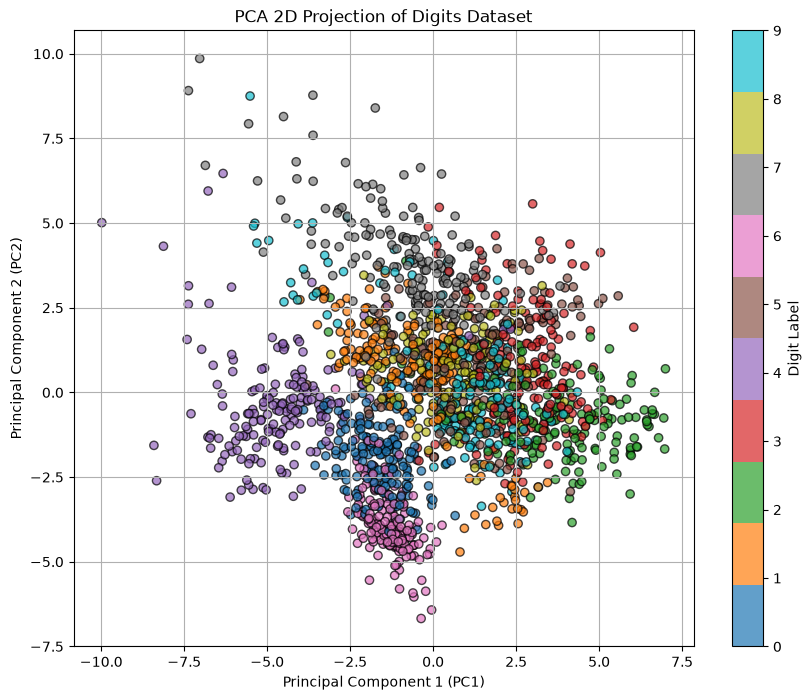

In [3]:
# 3. 시각화 목적: 64차원 -> 2차원으로 차원 축소
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

print(f"축소된 데이터 형태: {X_pca_2d.shape}")

# 2차원 산점도 시각화
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap='tab10', alpha=0.7, edgecolor='k')
plt.colorbar(scatter, label='Digit Label')
plt.title('PCA 2D Projection of Digits Dataset')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.grid(True)
plt.show()

In [4]:
# 4. 원본 정보의 95% 이상을 유지하는 차원 수 탐색 및 변환
pca_95 = PCA(n_components=0.95) # 95% 분산을 설명할 때까지의 주성분 자동 선택
X_pca_95 = pca_95.fit_transform(X_scaled)

print(f"원본 차원: {X.shape[1]}")
print(f"95% 정보 유지에 필요한 주성분(차원) 개수: {X_pca_95.shape[1]}")
print(f"설명된 분산의 비율(Explained Variance Ratio) 총합: {np.sum(pca_95.explained_variance_ratio_):.4f}")

원본 차원: 64
95% 정보 유지에 필요한 주성분(차원) 개수: 40
설명된 분산의 비율(Explained Variance Ratio) 총합: 0.9508
